In [1]:
# ============================================================
# IMPORT LIBRARIES
# ============================================================

import tensorflow as tf
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import OneHotEncoder, MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import precision_score, recall_score, f1_score




In [2]:
# ============================================================
# LOAD DATASET
# ============================================================

# Get current folder where script is running
current_dir = os.getcwd()

file_name = "synthetic_coffee_health_10000.csv"
file_path = os.path.join(current_dir, file_name)

# Load dataset into a pandas DataFrame (like Excel table)
coffee_health = pd.read_csv(file_path)

# Fill missing values in Health_Issues column
coffee_health['Health_Issues'] = coffee_health['Health_Issues'].fillna('No_Issues')

# Convert integer columns into float (better for neural networks)
coffee_health = coffee_health.astype({
    col: float for col in coffee_health.select_dtypes('int').columns
})




In [3]:
# ============================================================
# SPLIT FEATURES AND TARGET
# ============================================================

# Target variable (what we want to predict)
Y_extract = coffee_health['Caffeine_mg']

# Remove ID column (not useful for learning)
coffee_health = coffee_health.drop(['ID'], axis=1)

# Features (input variables)
X = coffee_health.drop(['Caffeine_mg'], axis=1)


# ============================================================
# BINNING TARGET (TURN REGRESSION INTO CLASSIFICATION)
# ============================================================

# Define caffeine ranges (classes)
bins = [0, 100, 200, 300, 400, 500, 600, 700, 800]

# Convert continuous caffeine values into class labels
# Example: 150 mg → class 1
Y_binned = np.digitize(Y_extract, bins=bins, right=False) - 1



In [4]:
# ============================================================
# TRAIN / TEST SPLIT (IMPORTANT: DONE BEFORE ENCODING)
# ============================================================

# stratify ensures each class is equally represented in train/test
X_train, X_test, Y_train, Y_test = train_test_split(
    X,
    Y_binned,
    test_size=0.2,
    random_state=42,
    stratify=Y_binned
)

In [5]:
# ============================================================
# ONE-HOT ENCODING (TEXT → NUMBERS)
# ============================================================

# Categorical (text) columns
categorical_cols = [
    "Gender",
    "Country",
    "Sleep_Quality",
    "Stress_Level",
    "Health_Issues",
    "Occupation"
]

# Create encoder (turn categories into binary columns)
ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False)

# Learn categories ONLY from training data (important to avoid leakage)
ohe.fit(X_train[categorical_cols])

# Transform training categorical data into numbers
X_train_ohe = pd.DataFrame(
    ohe.transform(X_train[categorical_cols]),
    columns=ohe.get_feature_names_out(categorical_cols),
    index=X_train.index
)

# Transform test data using SAME encoder
X_test_ohe = pd.DataFrame(
    ohe.transform(X_test[categorical_cols]),
    columns=ohe.get_feature_names_out(categorical_cols),
    index=X_test.index
)

# Remove original text columns (now encoded)
X_train = X_train.drop(columns=categorical_cols)
X_test = X_test.drop(columns=categorical_cols)

# Combine numeric + encoded features
X_train = pd.concat([X_train, X_train_ohe], axis=1)
X_test = pd.concat([X_test, X_test_ohe], axis=1)


In [6]:
# ============================================================
# FEATURE SCALING (NORMALIZE NUMBERS)
# ============================================================

# Columns that need scaling (make values 0–1)
cols_to_scale = [
    'Age',
    'Coffee_Intake',
    'Sleep_Hours',
    'BMI',
    'Heart_Rate',
    'Physical_Activity_Hours'
]

scaler = MinMaxScaler()

# Fit scaler ONLY on training data (important rule)
X_train[cols_to_scale] = scaler.fit_transform(X_train[cols_to_scale])

# Apply same scaling to test data
X_test[cols_to_scale] = scaler.transform(X_test[cols_to_scale])


In [7]:
# ============================================================
# BUILD NEURAL NETWORK MODEL
# ============================================================

# Number of output classes (depends on binning)
num_classes = len(np.unique(Y_train))

model = tf.keras.Sequential([

    # Input layer (number of features)
    layers.Input(shape=(X_train.shape[1],)),

    # Hidden layer 1
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.3),  # prevents overfitting

    # Hidden layer 2
    layers.Dense(32, activation="relu"),
    layers.Dropout(0.2),

    # Output layer (one neuron per class)
    layers.Dense(num_classes, activation="softmax")
])
model.summary()









Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         3,072 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 8)              │           264 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,416 (21.16 KB)

 Trainable params: 5,416 (21.16 KB)

 Non-trainable params: 0 (0.00 B)

In [8]:
# Compile model (define how it learns)
model.compile(
    optimizer="adam",  # adaptive optimizer
    loss="sparse_categorical_crossentropy",  # for integer class labels
    metrics=["accuracy"]
)


# ============================================================
# EARLY STOPPING (PREVENT OVERFITTING)
# ============================================================

early_stopping = EarlyStopping(
    monitor='val_loss',  # watch validation loss
    patience=5,          # stop if no improvement for 5 epochs
    restore_best_weights=True  # keep best model
)

In [9]:
# ============================================================
# TRAIN MODEL
# ============================================================

history = model.fit(
    X_train,
    Y_train,
    validation_split=0.2,  # 20% of training data used for validation
    epochs=100,
    batch_size=32,
    callbacks=[early_stopping],
    verbose=1
)


Epoch 1/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.2547 - loss: 1.7353 - val_accuracy: 0.3162 - val_loss: 1.5854
Epoch 2/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.3345 - loss: 1.5192 - val_accuracy: 0.4856 - val_loss: 1.2917
Epoch 3/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.4636 - loss: 1.2406 - val_accuracy: 0.7356 - val_loss: 0.9640
Epoch 4/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.5903 - loss: 0.9895 - val_accuracy: 0.8037 - val_loss: 0.7476
Epoch 5/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.6622 - loss: 0.8252 - val_accuracy: 0.8275 - val_loss: 0.6112
Epoch 6/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.7088 - loss: 0.7103 - val_accuracy: 0.8637 - val_loss: 0.5222
Epoch 7/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.7520 - loss: 0.6230 - val_accuracy: 0.8963 - val_loss: 0.4436
Epoch 8/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.7709 - loss: 0.5650 - val_a

In [12]:
# ============================================================
# EVALUATION
# ============================================================

# Predict class probabilities → convert to class labels
Y_pred = np.argmax(model.predict(X_test), axis=1)

# Evaluate loss and accuracy on TEST set
test_loss, test_accuracy = model.evaluate(X_test, Y_test, verbose=0)

# Get TRAINING accuracy (last epoch value)
train_accuracy = history.history['accuracy'][-1]

# Additional performance metrics
precision = precision_score(Y_test, Y_pred, average='weighted')
recall = recall_score(Y_test, Y_pred, average='weighted')
f1 = f1_score(Y_test, Y_pred, average='weighted')

# Print results
print(f"Training Accuracy: {train_accuracy:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1 Score: {f1:.4f}")



63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
Training Accuracy: 0.9023
Test Accuracy: 0.9430
Precision: 0.9391
Recall: 0.9430
F1 Score: 0.9404


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


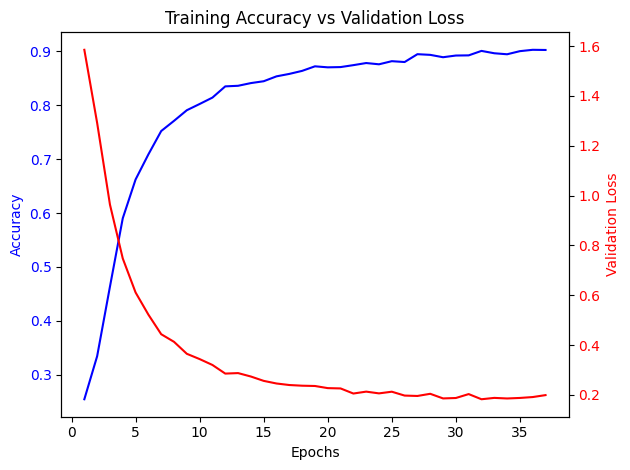

In [14]:
# ============================================================
# PLOT TRAINING RESULTS
# ============================================================

# Epochs
epochs = range(1, len(history.history['accuracy']) + 1)

# Create figure
fig, ax1 = plt.subplots()

# --------------------------------------------------
# Training Accuracy (left y-axis)
# --------------------------------------------------
ax1.plot(
    epochs,
    history.history['accuracy'],
    label='Training Accuracy',
    color='blue'
)

ax1.set_xlabel("Epochs")
ax1.set_ylabel("Accuracy", color='blue')
ax1.tick_params(axis='y', labelcolor='blue')

# --------------------------------------------------
# Validation Loss (right y-axis)
# --------------------------------------------------
ax2 = ax1.twinx()

ax2.plot(
    epochs,
    history.history['val_loss'],
    label='Validation Loss',
    color='red'
)

ax2.set_ylabel("Validation Loss", color='red')
ax2.tick_params(axis='y', labelcolor='red')

# --------------------------------------------------
# Title and legend
# --------------------------------------------------
plt.title("Training Accuracy vs Validation Loss")

fig.tight_layout()
plt.show()

In [15]:
from collections import Counter
import numpy as np

print("True class distribution:")
print(Counter(Y_test))

print("\nPredicted class distribution:")
print(Counter(Y_pred))

True class distribution:
Counter({np.int64(2): 551, np.int64(1): 461, np.int64(3): 397, np.int64(0): 341, np.int64(4): 181, np.int64(5): 55, np.int64(6): 12, np.int64(7): 2})

Predicted class distribution:
Counter({np.int64(2): 547, np.int64(1): 455, np.int64(3): 383, np.int64(0): 354, np.int64(4): 188, np.int64(5): 73})
